# Universidad Externado de Colombia · Visualización I
## Tarea preparatoria de la sesión 24
### Reto de visualización con Python: Seaborn y Plotly

**Modalidad:** individual · **Tiempo sugerido:** 40 minutos · **Evaluación:** cuestionario autocalificable en Moodle (10 preguntas, 5,0 puntos).

**Propósito:** preparar y explorar registros de la Línea 123 de Bogotá correspondientes a agosto de 2026, construir visualizaciones con Seaborn y Plotly y responder las preguntas de Moodle.

**Antes de empezar**
1. Abre este Notebook en **Google Colab** y selecciona **Archivo → Guardar una copia en Drive**.
2. Descarga el archivo `llamadaslinea123agosto2026.csv` desde Moodle y cárgalo cuando se solicite.
3. Ejecuta las celdas en orden. Las secciones incluyen actividades marcadas como **TU RETO**.
4. Responde en Moodle; **no escribas las respuestas en el Notebook**. No necesitas entregar este archivo.
5. Puedes consultar los materiales de clase. No modifiques el CSV original.

> **Importante:** cada fila representa un registro de desplazamiento y un mismo `NUMERO_INCIDENTE` puede repetirse. No confundas registros con incidentes únicos.

## 0. Preparación del entorno y carga de datos
Ejecuta estas dos celdas antes de empezar. En Colab se abrirá el selector de archivos. Si trabajas localmente, el código buscará el CSV en la carpeta de trabajo.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

MAGENTA = "#CB2F60"
GRIS = "#333333"
PALETA = ["#CB2F60", "#E88BA7", "#8B8B8B", "#D6D6D6"]
sns.set_theme(style="whitegrid", context="notebook")

archivo = "llamadaslinea123agosto2026.csv"
if not Path(archivo).exists():
    try:
        from google.colab import files
        print("Selecciona el CSV original de agosto de 2026:")
        archivos = files.upload()
        if archivo not in archivos:
            raise FileNotFoundError(f"Debes cargar el archivo llamado {archivo}.")
    except ImportError:
        raise FileNotFoundError(f"Ubica {archivo} en la carpeta de trabajo.")

df_original = pd.read_csv(archivo, sep=";", encoding="utf-8-sig", low_memory=False)
print("Archivo cargado. Columnas disponibles:")
print(df_original.columns.tolist())
print("Vista preliminar:")
display(df_original.head(3))

Selecciona el CSV original de agosto de 2026:


Saving llamadaslinea123agosto2026.csv to llamadaslinea123agosto2026.csv
Archivo cargado. Columnas disponibles:
['NUMERO_INCIDENTE', 'FECHA_INICIO_DESPLAZAMIENTO_MOVIL', 'CODIGO_LOCALIDAD', 'LOCALIDAD', 'EDAD', 'UNIDAD', 'GENERO', 'TIPO_INCIDENTE', 'PRIORIDAD_FINAL', 'RECEPCION']
Vista preliminar:


,NUMERO_INCIDENTE,FECHA_INICIO_DESPLAZAMIENTO_MOVIL,CODIGO_LOCALIDAD,LOCALIDAD,EDAD,UNIDAD,GENERO,TIPO_INCIDENTE,PRIORIDAD_FINAL,RECEPCION
0,CRU-00404226-26,1/08/2026 0:01,10,ENGATIVÁ,NaN,NaN,NaN,ACOMPAÑAMIENTO A EVENTO,Baja,NaN
1,CRU-00404226-26,1/08/2026 7:14,10,ENGATIVÁ,NaN,NaN,NaN,ACOMPAÑAMIENTO A EVENTO,Baja,NaN
2,CRU-00404227-26,1/08/2026 0:02,14,LOS MÁRTIRES,NaN,NaN,NaN,ACOMPAÑAMIENTO A EVENTO,Baja,NaN


### Preparación común: fechas y datos de agosto
Esta celda realiza la conversión de fechas y prepara una copia de agosto. **No elimina filas con valores faltantes de otras variables**, porque podrían ser útiles para ciertos análisis.

**TU RETO (pregunta 1 de Moodle):** ejecuta la celda y utiliza el número de registros de `datos_agosto` para responder la pregunta. La instrucción que imprime ese número está incompleta: reemplaza `...` por la expresión adecuada.

In [2]:
df = df_original.copy()
df["fecha"] = pd.to_datetime(
    df["FECHA_INICIO_DESPLAZAMIENTO_MOVIL"],
    dayfirst=True,
    errors="coerce"
)

inicio = pd.Timestamp("2026-08-01")
fin_exclusivo = pd.Timestamp("2026-09-01")
mascara_agosto = df["fecha"].ge(inicio) & df["fecha"].lt(fin_exclusivo)
datos_agosto = df.loc[mascara_agosto].copy()

# TU RETO: reemplaza los puntos por la instrucción de conteo de filas.
# Ejemplo de sintaxis útil: len(nombre_del_dataframe)
# print("Registros de agosto:", ...)

print("Fechas mínima y máxima de agosto:",
      datos_agosto["fecha"].min(), datos_agosto["fecha"].max())

Fechas mínima y máxima de agosto: 2026-08-01 00:01:00 2026-08-31 23:58:00


## 1. Calidad de datos · Pregunta 2 (Moodle)
**TU RETO:** examina los valores faltantes por columna. Piensa qué sucede si se ejecuta `dropna()` **sin especificar columnas** y luego se intenta estudiar la distribución por localidad.

Ejecuta la celda y responde en Moodle la pregunta conceptual aplicada.

In [3]:
faltantes = datos_agosto.isna().sum().sort_values(ascending=False)
display(faltantes.to_frame("Valores faltantes"))

# Compara el tamaño de ambos conjuntos; no sobreescribas datos_agosto.
sin_faltantes_en_todas = datos_agosto.dropna()
print("Filas originales de agosto:", len(datos_agosto))
print("Filas tras eliminar cualquier valor faltante:", len(sin_faltantes_en_todas))

# TU RETO: explica mentalmente por qué se pierden registros
# que sí tienen una localidad válida.

,Valores faltantes
RECEPCION,4088
EDAD,3064
GENERO,3063
UNIDAD,3063
CODIGO_LOCALIDAD,0
NUMERO_INCIDENTE,0
FECHA_INICIO_DESPLAZAMIENTO_MOVIL,0
LOCALIDAD,0
TIPO_INCIDENTE,0
PRIORIDAD_FINAL,0


Filas originales de agosto: 9200
Filas tras eliminar cualquier valor faltante: 5111


## 2. Seaborn · Ranking de localidades · Pregunta 3
**TU RETO:** completa la instrucción de ordenamiento para obtener un ranking de mayor a menor frecuencia. Después construye el gráfico y consulta en Moodle el valor solicitado.

**Sugerencia:** `sort_values(ascending=False)` ordena una serie de frecuencias de mayor a menor.

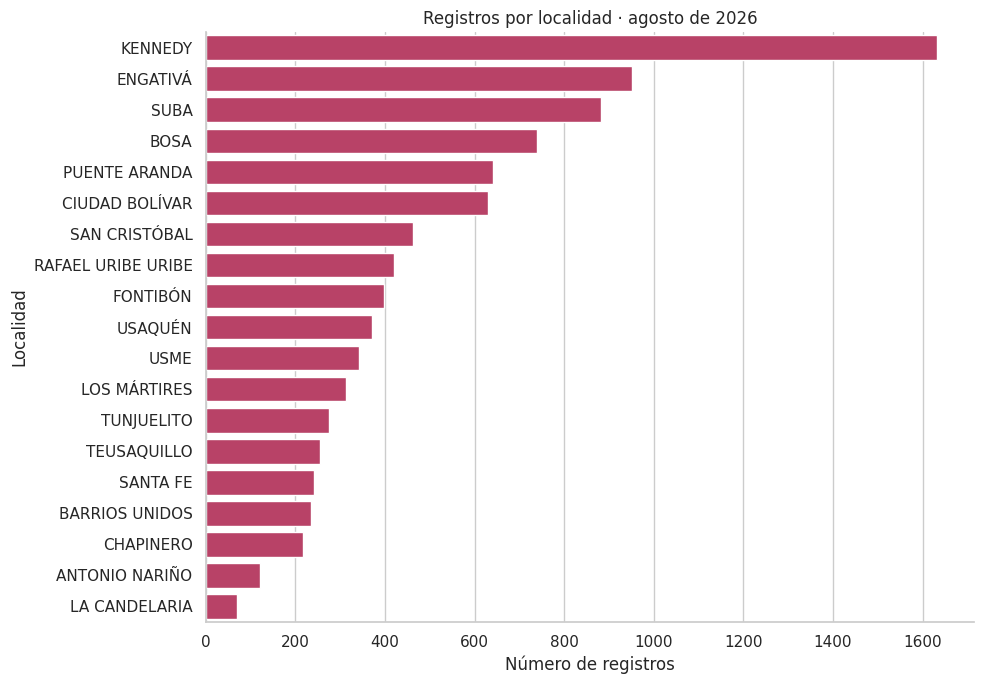

In [4]:
frecuencia_localidad = datos_agosto["LOCALIDAD"].value_counts()

# TU RETO: activa la línea siguiente reemplazando los puntos.
# ranking = frecuencia_localidad.sort_values(ascending=...)

# Mientras completas el reto, puedes ejecutar el gráfico usando
# la serie de frecuencias; value_counts() ya devuelve orden descendente.
ranking = frecuencia_localidad

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=ranking.values, y=ranking.index, color=MAGENTA, ax=ax)
ax.set(title="Registros por localidad · agosto de 2026",
       xlabel="Número de registros", ylabel="Localidad")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# TU RETO: consulta el ranking sin copiar sus valores en Moodle automáticamente.
# display(ranking.head(5))

## 3. Seaborn · Comparación de prioridades · Pregunta 4
**TU RETO:** genera un gráfico de barras de prioridades y ejecuta la instrucción que muestra sus frecuencias. En Moodle deberás **emparejar** cada categoría con su frecuencia.

Para ordenar conceptualmente las prioridades usa: **Crítica → Alta → Media → Baja**. En el CSV la categoría `Critica` puede aparecer sin tilde; se normaliza solo para mostrarla.

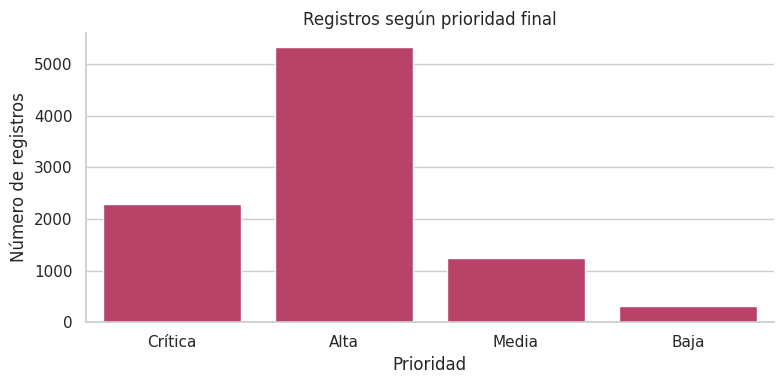

In [5]:
datos_prioridad = datos_agosto.copy()
datos_prioridad["prioridad_etiqueta"] = (
    datos_prioridad["PRIORIDAD_FINAL"].astype("string")
    .str.strip().replace({"Critica": "Crítica"})
)
orden_prioridad = ["Crítica", "Alta", "Media", "Baja"]
conteos_prioridad = (
    datos_prioridad["prioridad_etiqueta"]
    .value_counts().reindex(orden_prioridad, fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=conteos_prioridad.index, y=conteos_prioridad.values,
            color=MAGENTA, ax=ax)
ax.set(title="Registros según prioridad final",
       xlabel="Prioridad", ylabel="Número de registros")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# TU RETO: quita el comentario para consultar los valores
# display(conteos_prioridad)

## 4. Seaborn · Distribución de edades · Pregunta 5
**TU RETO:** construye e interpreta un histograma. Identifica cómo afectan al análisis los registros sin edad.

Solo se excluyen valores faltantes de `EDAD`, **no** filas con valores faltantes en otras columnas. Ajusta `bins` de 10 a 20 y observa qué cambia y qué no cambia.

Observaciones con edad válida: 6136
Observaciones sin edad válida: 3064


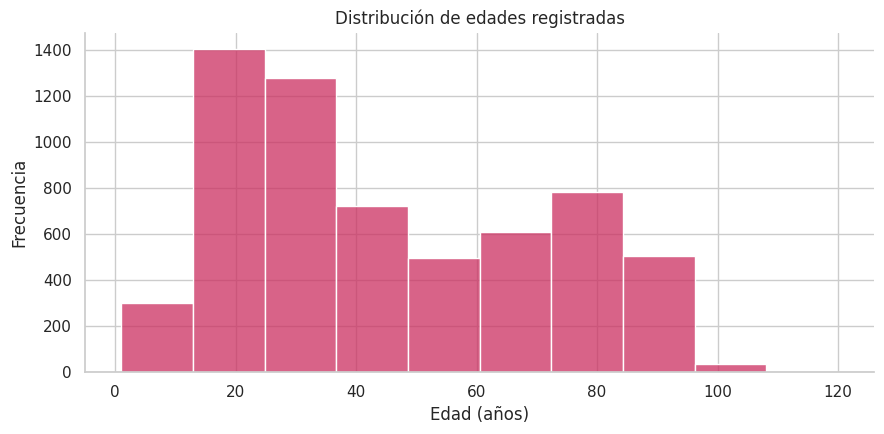

In [6]:
edades = pd.to_numeric(datos_agosto["EDAD"], errors="coerce")
edades_validas = edades.dropna()

print("Observaciones con edad válida:", edades_validas.size)
print("Observaciones sin edad válida:", edades.isna().sum())

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(edades_validas, bins=10, color=MAGENTA,
             edgecolor="white", ax=ax)
ax.set(title="Distribución de edades registradas",
       xlabel="Edad (años)", ylabel="Frecuencia")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# TU RETO: cambia bins=10 por bins=20 y vuelve a ejecutar.
# ¿El histograma representa a todas las filas de agosto?

## 5. Plotly · Información emergente · Pregunta 6
**TU RETO:** pasa el cursor sobre las barras. Observa qué información adicional presenta Plotly y responde la pregunta de verdadero/falso en Moodle.

In [7]:
tabla_tipos = (
    datos_agosto["TIPO_INCIDENTE"].value_counts()
    .rename_axis("tipo_incidente").reset_index(name="registros")
    .head(10)
)
fig_hover = px.bar(
    tabla_tipos, x="registros", y="tipo_incidente",
    orientation="h", color_discrete_sequence=[MAGENTA],
    hover_data={"tipo_incidente": True, "registros": True},
    title="Tipos de incidente con mayor frecuencia"
)
fig_hover.update_layout(yaxis={"categoryorder": "total ascending"},
                        xaxis_title="Registros", yaxis_title="Tipo de incidente",
                        font_color=GRIS)
fig_hover.show()

## 6. Plotly · Selección rectangular y lazo · Pregunta 7
**TU RETO:** ejecuta el gráfico de dispersión. Primero selecciona puntos mediante un rectángulo y después cambia `dragmode` a `lasso`. En Moodle identificarás el valor correcto para activar la selección rectangular.

Para recuperar el zoom utiliza los controles de la barra de herramientas.

In [8]:
# Agrupar por día y prioridad para tener puntos comparables.
datos_dia_prioridad = datos_agosto.copy()
datos_dia_prioridad["dia_mes"] = datos_dia_prioridad["fecha"].dt.day
puntos = (datos_dia_prioridad.groupby(["dia_mes", "PRIORIDAD_FINAL"])
          .size().reset_index(name="registros"))

fig_seleccion = px.scatter(
    puntos, x="dia_mes", y="registros", color="PRIORIDAD_FINAL",
    hover_data=["PRIORIDAD_FINAL"],
    title="Registros diarios según prioridad",
    labels={"dia_mes": "Día de agosto", "registros": "Registros", "PRIORIDAD_FINAL": "Prioridad"},
    color_discrete_sequence=[MAGENTA, "#E88BA7", "#666666", "#BDBDBD"]
)
fig_seleccion.update_traces(marker={"size": 10, "opacity": 0.85})
fig_seleccion.update_layout(
    dragmode="select",  # TU RETO: cambia temporalmente a "lasso"
    hovermode="closest",
    hoverdistance=30,
    font_color=GRIS
)
fig_seleccion.show()

## 7. Plotly · Evolución diaria · Pregunta 8
**TU RETO:** construye una serie temporal interactiva, utiliza el cursor para identificar el día con mayor frecuencia y responde en Moodle el **número de registros** de ese día.

No confundas el valor del eje vertical (registros) con el número de incidentes únicos.

In [9]:
serie_diaria = (
    datos_agosto.groupby(datos_agosto["fecha"].dt.normalize())
    .size().rename("registros").reset_index()
    .rename(columns={"fecha": "dia"})
)
fig_temporal = px.line(
    serie_diaria, x="dia", y="registros", markers=True,
    title="Evolución diaria de registros · agosto de 2026",
    color_discrete_sequence=[MAGENTA],
    labels={"dia": "Fecha", "registros": "Número de registros"}
)
fig_temporal.update_traces(hovertemplate="%{x|%d/%m/%Y}<br>Registros: %{y}<extra></extra>")
fig_temporal.update_layout(hovermode="x unified", font_color=GRIS)
fig_temporal.show()

# TU RETO: si el cursor no permite distinguir bien el máximo,
# consulta el ordenamiento de serie_diaria sin alterar los datos.
# display(serie_diaria.sort_values("registros", ascending=False).head())

## 8. Plotly · Corrección de errores · Pregunta 9
Un gráfico puede mostrar los días **en un orden incorrecto** si las fechas se convierten a cadenas y se ordenan alfabéticamente.

**TU RETO:** ejecuta primero la versión incorrecta. Después ejecuta la versión corregida y responde en Moodle qué modificación recupera el orden cronológico.

In [10]:

# ============================================================
# SECCIÓN 9. DETECCIÓN Y CORRECCIÓN DE ERRORES
# ============================================================
# Objetivo:
# Identificar y corregir un problema de orden cronológico
# en una visualización interactiva con Plotly.
#
# El primer gráfico contiene un error intencional.
# Para generar el segundo gráfico, debes completar
# los pasos 2 y 3.
# ============================================================


# ------------------------------------------------------------
# 1. VERSIÓN INCORRECTA
# ------------------------------------------------------------

# Crear una copia de los registros diarios.
serie_mal = serie_diaria.copy()

# Convertir las fechas a texto.
serie_mal["etiqueta"] = serie_mal["dia"].dt.strftime("%d/%m/%Y")

# Ordenar las etiquetas en sentido descendente.
serie_mal = serie_mal.sort_values(
    "etiqueta",
    ascending=False
)

# Construir el gráfico incorrecto.
fig_mal = px.line(
    serie_mal,
    x="etiqueta",
    y="registros",
    markers=True,
    title="Versión incorrecta: eje temporal como texto",
    color_discrete_sequence=[MAGENTA]
)

fig_mal.update_layout(
    xaxis_title="Fecha (texto)",
    yaxis_title="Registros"
)

fig_mal.show()


# ------------------------------------------------------------
# 2. VERSIÓN CORREGIDA: RETO PARA EL ESTUDIANTE
# ------------------------------------------------------------

# PASO 1. Crear una copia de los datos del gráfico incorrecto.
# Eliminamos la columna original de fechas para reconstruirla.
serie_bien = serie_mal.drop(columns=["dia"]).copy()


# PASO 2. Convertir las etiquetas de texto a fechas.
# TU RETO:
# Completa la instrucción utilizando pd.to_datetime().
# Recuerda que las fechas tienen formato día/mes/año.

# serie_bien["dia"] = ...


# PASO 3. Ordenar cronológicamente los registros.
# TU RETO:
# Completa la instrucción utilizando sort_values()
# y la columna "dia".

# serie_bien = ...


# ------------------------------------------------------------
# 3. VERIFICACIÓN Y VISUALIZACIÓN CORREGIDA
# ------------------------------------------------------------

# Comprobar si el estudiante completó correctamente el reto.
if "dia" not in serie_bien.columns:
    print(
        "RETO PENDIENTE: convierte las etiquetas de texto "
        "a fechas utilizando pd.to_datetime()."
    )

elif not pd.api.types.is_datetime64_any_dtype(serie_bien["dia"]):
    print(
        "RETO PENDIENTE: la columna 'dia' debe tener "
        "un formato de fecha válido."
    )

elif not serie_bien["dia"].is_monotonic_increasing:
    print(
        "RETO PENDIENTE: ordena cronológicamente "
        "los registros utilizando sort_values()."
    )

else:
    # Construir el gráfico corregido.
    fig_bien = px.line(
        serie_bien,
        x="dia",
        y="registros",
        markers=True,
        title="Versión corregida: eje temporal cronológico",
        color_discrete_sequence=[MAGENTA]
    )

    fig_bien.update_layout(
        xaxis_title="Fecha",
        yaxis_title="Registros"
    )

    fig_bien.show()

    print("¡Reto completado! Las fechas están ordenadas cronológicamente.")


RETO PENDIENTE: convierte las etiquetas de texto a fechas utilizando pd.to_datetime().


## 9. Diseño visual · Pregunta 10
Compara las dos versiones del ranking. **TU RETO:** observa la organización de las categorías, el uso del color, las etiquetas y la facilidad de lectura. Responde en Moodle cuál versión comunica mejor la comparación y por qué.

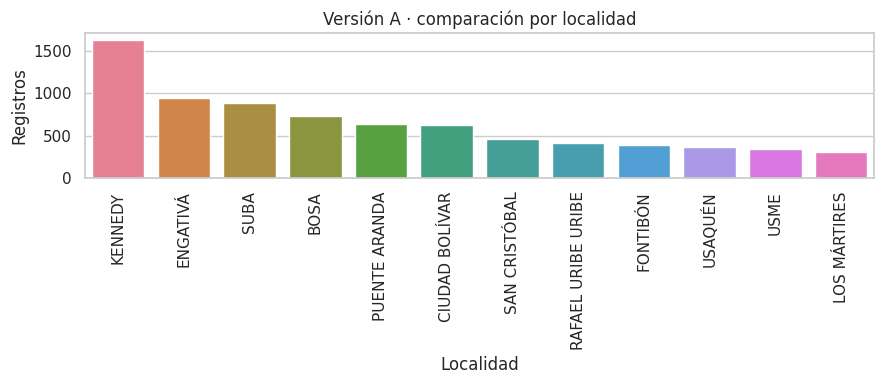

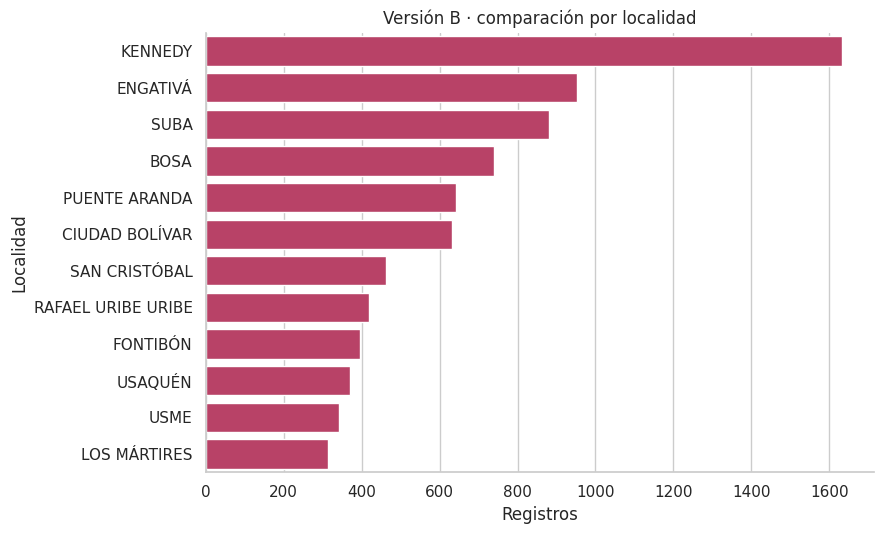

In [11]:
comparacion = datos_agosto["LOCALIDAD"].value_counts().head(12)

# VERSIÓN A: etiquetas largas en vertical y colores múltiples.
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=comparacion.index, y=comparacion.values,
            hue=comparacion.index, palette="husl", dodge=False,
            legend=False, ax=ax)
ax.set(title="Versión A · comparación por localidad", xlabel="Localidad", ylabel="Registros")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

# VERSIÓN B: barras horizontales ordenadas y color uniforme.
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=comparacion.values, y=comparacion.index,
            color=MAGENTA, ax=ax)
ax.set(title="Versión B · comparación por localidad", xlabel="Registros", ylabel="Localidad")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Cierre de la tarea
Antes de finalizar, verifica que:

- Ejecutaste las secciones de Seaborn y Plotly.
- Respondiste las **10 preguntas** en Moodle.
- Interpretaste las frecuencias como **registros**, salvo que una pregunta indique explícitamente **incidentes únicos**.
- Identificaste la importancia del filtrado temporal, los datos faltantes y la legibilidad.

**La actividad de la sesión 25 será diferente:** en el laboratorio de investigación tendrás que aplicar estas habilidades con mayor autonomía.

> Este Notebook es un recurso de trabajo; **la calificación se registra en Moodle**.